# Identificação do projeto

**Título do projeto:** Analise do mercado de jogos na Steam  

**Integrantes do grupo:** Gustavo Delinski Tavares, Eduardo Jabur
**Turma:** Turma 6° GCL1

**Descrição breve do problema ou contexto:** Análise de dados públicos da Steam para entender quais gêneros de jogos mantêm os jogadores por mais tempo, quais gêneros mais cresceram em lançamentos e como jogos gratuitos e pagos se comparam em popularidade.

Notebook integrado dos RAs 1, 2 e 3, seguindo o template da disciplina. As explicações, implementações e resultados estão nas seções correspondentes.


## Instruções de execução
Abra este notebook no Google Colab e execute as células em ordem. Fora do Colab, use Python 3.12,
Java 17 ou 21 para o Spark e instale: `python -m pip install pandas==2.2.3 numpy==2.1.2 matplotlib==3.9.2 seaborn==0.13.2 scikit-learn==1.6.1 pyspark==4.0.1 requests==2.32.3 kagglehub==0.3.13`.
O RA1 gera `steam_games_limpo.csv`; não é necessário versionar o CSV. A base bruta é baixada
da versão 59 do Kaggle ou lida de `games.csv` local. As consultas do RA2 exigem internet.
Para executar somente RA3, rode os imports e carregue o CSV já gerado; as células 3.1 a 3.5 não dependem do Spark.


---

# RA1 — Data Ingestion, Cleaning and Initial Analysis

Nesta etapa, carregue, prepare e explore os dados do projeto.

## 1. Contexto e objetivo

Apresente brevemente o problema investigado e o que o grupo pretende descobrir com os dados.

**Resposta do grupo:**

A Steam é a maior loja de jogos para PC e recebe dezenas de milhares de lançamentos por ano (quase 25 mil só em 2025, segundo a base usada). Com tanta concorrência, entender quais tipos de jogo prendem os jogadores e quais gêneros estão crescendo ajuda desenvolvedores a decidir o que produzir.

O projeto vai investigar três perguntas:

- **P1:** Quais gêneros apresentam maior tempo mediano de jogo por jogador?
- **P2:** Quais gêneros tiveram maior crescimento no número de lançamentos entre 2020 e 2025?
- **P3:** Entre os 100 jogos com mais donos estimados, como gratuitos e pagos se comparam em pico de jogadores simultâneos e proporção de avaliações positivas?

Usamos o tempo de jogo como aproximação de retenção, já que a base não tem dados de jogadores voltando ao jogo ao longo do tempo. O recorte da P2 termina em 2025 porque é o último ano completo na base.

## 2. Fonte e ingestão dos dados

- Identifique a fonte dos dados, incluindo link ou referência de acesso.
- Descreva brevemente o dataset e o que seus registros representam.
- Explique como os dados foram carregados e implemente a ingestão.

**Resposta do grupo:**

**Fonte:** Steam Games Dataset, publicado no Kaggle por FronkonGames: https://www.kaggle.com/datasets/fronkongames/steam-games-dataset. Os dados foram coletados da API da Steam e do SteamSpy, na cópia histórica identificada pelo SHA-256 na célula de ingestão.

**O que cada registro representa:** um item da loja Steam (na maioria jogos, mas também softwares e vídeos). São 125.855 registros e 40 colunas, com informações de preço, data de lançamento, gêneros, avaliações, donos estimados e tempo de jogo. A base vem em CSV e JSON; usamos só o CSV.

**Ingestão:** implementamos uma abordagem mista. O código tenta primeiro baixar o dataset automaticamente usando a biblioteca `kagglehub`. Caso ocorra alguma falha no download (como instabilidade ou erro na extração do arquivo), ele utiliza um fallback e lê o arquivo inserido manualmente no ambiente (`/content/games.csv`). Caso precise usar o fallback, você pode **[baixar o dataset diretamente do Kaggle clicando aqui](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset/download)** (é necessário extrair o `.zip` e fazer o upload do `games.csv` no menu lateral do Colab).

Na primeira leitura, o pandas encontrou 39 nomes de coluna para 40 valores por linha. O cabeçalho tinha as colunas Discount e DLC count unidas em "DiscountDLC count", o que deslocava todos os valores uma coluna para a esquerda. Corrigimos lendo o arquivo com a lista de nomes ajustada, sem alterar o arquivo original.
A versão 59 é fixada para reproduzir a cópia histórica. O CSV bruto é verificado pelo hash; a data exata da coleta não é comprovada apenas pelas datas de lançamento.


In [1]:
import sys, subprocess, hashlib
from pathlib import Path
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','pandas==2.2.3','numpy==2.1.2',
        'matplotlib==3.9.2','seaborn==0.13.2','scikit-learn==1.6.1','pyspark==4.0.1',
        'requests==2.32.3','kagglehub==0.3.13'])
import pandas as pd
import kagglehub
HASH_BRUTO='1b48008b01a799d82385d6e66ba0cb65dd477b6aa4b6c2ec8c443025ab6880ad'
candidatos=[Path('games.csv'),Path('/content/games.csv')]
caminho_csv=next((p for p in candidatos if p.is_file()),None)
if caminho_csv is None:
    caminho_csv=Path(kagglehub.dataset_download('fronkongames/steam-games-dataset/versions/59',path='games.csv'))
    if caminho_csv.is_dir():caminho_csv=caminho_csv/'games.csv'
with caminho_csv.open('rb') as arquivo:
    hash_obtido=hashlib.file_digest(arquivo,'sha256').hexdigest()
if hash_obtido!=HASH_BRUTO:
    raise ValueError('O CSV difere da cópia histórica: obtenha a versão documentada antes de executar.')
df=pd.read_csv(caminho_csv)
print('Formato da primeira leitura:',df.shape)
print('SHA-256 conferido:',hash_obtido)


C:\Users\Gustavo\Documents\Codex\2026-11-16\voc\work\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Formato da primeira leitura: (125855, 39)
SHA-256 conferido: 1b48008b01a799d82385d6e66ba0cb65dd477b6aa4b6c2ec8c443025ab6880ad


In [2]:
df.columns.tolist()

['AppID',
 'Name',
 'Release date',
 'Estimated owners',
 'Peak CCU',
 'Required age',
 'Price',
 'DiscountDLC count',
 'About the game',
 'Supported languages',
 'Full audio languages',
 'Reviews',
 'Header image',
 'Website',
 'Support url',
 'Support email',
 'Windows',
 'Mac',
 'Linux',
 'Metacritic score',
 'Metacritic url',
 'User score',
 'Positive',
 'Negative',
 'Score rank',
 'Achievements',
 'Recommendations',
 'Notes',
 'Average playtime forever',
 'Average playtime two weeks',
 'Median playtime forever',
 'Median playtime two weeks',
 'Developers',
 'Publishers',
 'Categories',
 'Genres',
 'Tags',
 'Screenshots',
 'Movies']

In [3]:
colunas = pd.read_csv(caminho_csv, nrows=0).columns.tolist()

i = colunas.index("DiscountDLC count")
colunas[i:i+1] = ["Discount", "DLC count"]

df = pd.read_csv(caminho_csv, header=None, skiprows=1, names=colunas)
print(df.shape)

(125855, 40)


## 3. Exploração inicial dos dados

Investigue a quantidade de registros e colunas, os tipos de dados, os valores ausentes e outras características relevantes da base.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  object 
 2   Release date                125855 non-null  object 
 3   Estimated owners            125855 non-null  object 
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  object 
 10  Supported languages         125855 non-null  object 
 11  Full audio languages        125855 non-null  object 
 12  Reviews                     12181 non-null   object 
 13  Header image  

In [5]:
df["Estimated owners"].value_counts()

Estimated owners
0 - 20000                75705
0 - 0                    24579
20000 - 50000            11397
50000 - 100000            5355
100000 - 200000           3454
200000 - 500000           2856
500000 - 1000000          1155
1000000 - 2000000          729
2000000 - 5000000          405
5000000 - 10000000         125
10000000 - 20000000         51
20000000 - 50000000         31
50000000 - 100000000         9
100000000 - 200000000        4
Name: count, dtype: int64

In [6]:
df.isna().sum().sort_values(ascending=False)

Movies                        125855
Score rank                    125815
Metacritic url                121597
Reviews                       113674
Notes                         102545
Website                        75335
Support url                    70560
Tags                           42502
Support email                  22630
Categories                      8966
Publishers                      8922
About the game                  8462
Developers                      8449
Genres                          8423
Screenshots                     6027
Header image                      81
Name                               1
Discount                           0
Required age                       0
Price                              0
Estimated owners                   0
Release date                       0
AppID                              0
Peak CCU                           0
Positive                           0
User score                         0
Metacritic score                   0
L

In [7]:
print((df["Median playtime forever"] == 0).mean())
print((df["Estimated owners"] == "0 - 0").mean())
print((df["Price"] == 0).mean())

0.7920384569544316
0.1952961741686862
0.21183902109570538


In [8]:
df["Release date"].sample(15, random_state=1)

55959     Apr 11, 2024
42009     Dec 22, 2023
51173      Nov 8, 2024
26675     Dec 20, 2016
51005     Jul 24, 2017
112101    Oct 23, 2024
34898     Mar 27, 2019
90039     Jul 12, 2025
22813      Oct 1, 2025
7139      Oct 23, 2025
29929     Jul 14, 2020
70677     May 10, 2017
52881     Aug 21, 2025
112812    Dec 20, 2020
18795      Mar 9, 2018
Name: Release date, dtype: object

In [9]:
datas = pd.to_datetime(df["Release date"], format="%b %d, %Y", errors="coerce")
print(datas.isna().sum())
print(datas.min())
print(datas.max())

0
1997-06-30 00:00:00
2026-12-01 00:00:00


In [10]:
datas.dt.year.value_counts().sort_index().tail(10)

Release date
2017     5922
2018     7461
2019     7243
2020     8804
2021    11067
2022    12288
2023    14598
2024    20033
2025    24973
2026     3316
Name: count, dtype: int64

In [11]:
datas[datas.dt.year >= 2025].dt.to_period("M").value_counts().sort_index()

Release date
2025-01    1680
2025-02    1629
2025-03    2087
2025-04    2092
2025-05    2040
2025-06    1999
2025-07    2264
2025-08    2188
2025-09    2111
2025-10    2564
2025-11    2410
2025-12    1909
2026-01    1565
2026-02    1706
2026-03      42
2026-06       1
2026-09       1
2026-12       1
Freq: M, Name: count, dtype: int64

In [12]:
df["Genres"].sample(10, random_state=1)

55959                                  Casual,Indie
42009                                           NaN
51173     Casual,Strategy,Free To Play,Early Access
26675                                    Simulation
51005                                  Action,Indie
112101           Casual,Indie,Strategy,Early Access
34898                                  Casual,Indie
90039            Action,Adventure,Casual,Simulation
22813             Action,Adventure,RPG,Free To Play
7139                                   Casual,Indie
Name: Genres, dtype: object

In [13]:
generos = df["Genres"].str.split(",").explode()
generos.value_counts()

Genres
Indie                    82884
Casual                   51677
Action                   47344
Adventure                46293
Simulation               24912
Strategy                 23058
RPG                      21577
Free To Play             12605
Early Access             11572
Sports                    4971
Racing                    4169
Massively Multiplayer     2596
Utilities                 1091
Design & Illustration      584
Animation & Modeling       484
Education                  464
Violent                    414
Video Production           340
Game Development           323
Gore                       257
Audio Production           229
Software Training          222
Photo Editing              183
Web Publishing             113
Nudity                      94
Sexual Content              88
Accounting                  32
Movie                        2
Documentary                  1
Episodic                     1
Short                        1
Tutorial                     1
3

In [14]:
generos_software = ["Utilities", "Design & Illustration", "Animation & Modeling",
                    "Video Production", "Game Development", "Audio Production",
                    "Software Training", "Web Publishing", "Photo Editing",
                    "Education", "Accounting", "Movie", "Documentary",
                    "Episodic", "Short", "Tutorial", "360 Video"]

rotulos_nao_genero = ["Violent", "Gore", "Nudity", "Sexual Content",
                      "Early Access", "Free To Play"]

lista = df["Genres"].dropna().str.split(",")

tem_software = lista.apply(lambda g: any(x in generos_software for x in g))
generos_de_jogo = lista.apply(lambda g: [x for x in g if x not in generos_software and x not in rotulos_nao_genero])
tem_jogo = generos_de_jogo.apply(len) > 0

print("Só software/vídeo:", (tem_software & ~tem_jogo).sum())
print("Misturam jogo e software:", (tem_software & tem_jogo).sum())
print("Sem nenhum gênero de jogo (só rótulos):", (~tem_software & ~tem_jogo).sum())

Só software/vídeo: 1491
Misturam jogo e software: 410
Sem nenhum gênero de jogo (só rótulos): 220


In [15]:
df.nlargest(5, "Median playtime forever")[["Name", "Median playtime forever"]]

,Name,Median playtime forever
27968,Avem33,3429544
59930,iTownGamePlay UNIVERSE,1714283
67121,Letters From a Rainy Day -Oceans and Lace-,359674
63635,爱人 Lover,322983
21667,Sisyphus Reborn,222407


In [16]:
print("AppID duplicado:", df["AppID"].duplicated().sum())
print("Nome duplicado:", df["Name"].duplicated().sum())
print("Nome + Dev + Data duplicado:", df.duplicated(subset=["Name", "Developers", "Release date"]).sum())

AppID duplicado: 0
Nome duplicado: 1210
Nome + Dev + Data duplicado: 111


**Resposta do grupo:**

O dataset possui 125.855 registros, cada linha é um item da loja Steam, e 40 colunas após a correção do cabeçalho. Os tipos incluem números inteiros (AppID E Peak CCU), decimais (Price), booleanos (Windows, Linux) e texto (Name, Genres, Release date, Estimated owners).

Principais problemas e características observadas:

1. Cabeçalho: as colunas Discount e DLC count vinham unidas em DiscountDLC count, deslocando todos os valores uma coluna para a esquerda. Corrigido na ingestão.

2. Valores ausentes: entre as colunas usadas no projeto, Genres tem 8.423 vazios e Name tem 1. Outras colunas com muitos vazios (Website, Metacritic url, Support email etc.) não são usadas nas perguntas.

3. Zeros que indicam falta de dado: 79% dos registros têm Median playtime forever = 0 e 19,5% têm Estimated owners = "0 - 0". Interpretamos como ausência de dado (a causa de cada zero não pode ser confirmada pelo CSV), não como valor real.

4. Zeros no preço: 21% dos registros têm Price = 0, mas notamos que nem todos são gratuitos (jogos legados e deslistados também recebem valor 0 na base de dados).

5. Estimated owners: está como texto em faixas (ex: "0 - 20000"), não como número.

6. Release date: está como texto no formato "Mon DD, YYYY" e converte para data sem falhas. A coleta vai até cerca de março de 2026, então 2026 está incompleto. Existem datas futuras (jogos anunciados, ainda não lançados).

7. Genres: vários gêneros por jogo em um único texto separado por vírgula. Há itens que não são jogos: 1.491 possuem apenas gêneros de software/vídeo, 410 misturam gêneros de jogo e de software, e 220 possuem apenas rótulos que não são gênero (ex: "Free To Play", "Early Access", "Violent").

8. Outliers: alguns jogos têm tempo
mediano de jogo implausível (ex: Avem33, cerca de 6,5 anos ininterruptos), sem causa confirmada na base.

9. Duplicados: não há AppID repetido.
 Nomes repetidos são, em geral, jogos diferentes com o mesmo nome. Porém, há registros com mesmo nome, desenvolvedor e data de lançamento, que representam o mesmo jogo cadastrado mais de uma vez.


## 4. Limpeza e preparação dos dados

Realize a limpeza necessária ao projeto. Verifique valores ausentes, duplicados e inconsistências e trate os problemas encontrados, quando necessário.

In [17]:
df_limpo = df.copy()

In [18]:
print("Tipo antes:", df_limpo["Estimated owners"].dtype)
print("Registros '0 - 0':", (df_limpo["Estimated owners"] == "0 - 0").sum())

faixas = df_limpo["Estimated owners"].str.split(" - ", expand=True).astype(int)
df_limpo["owners_min"] = faixas[0]
df_limpo["owners_max"] = faixas[1]
df_limpo["owners_medio"] = (faixas[0] + faixas[1]) / 2

sem_dado = df_limpo["Estimated owners"] == "0 - 0"
df_limpo.loc[sem_dado, ["owners_min", "owners_max", "owners_medio"]] = None

print("Tipo depois:", df_limpo["owners_medio"].dtype)
print("Vazios em owners_medio:", df_limpo["owners_medio"].isna().sum())
df_limpo[["Estimated owners", "owners_min", "owners_max", "owners_medio"]].sample(5, random_state=1)

Tipo antes: object
Registros '0 - 0': 24579


Tipo depois: float64
Vazios em owners_medio: 24579


,Estimated owners,owners_min,owners_max,owners_medio
55959,20000 - 50000,20000.0,50000.0,35000.0
42009,0 - 20000,0.0,20000.0,10000.0
51173,0 - 20000,0.0,20000.0,10000.0
26675,0 - 20000,0.0,20000.0,10000.0
51005,20000 - 50000,20000.0,50000.0,35000.0


In [19]:
col = "Median playtime forever"
print("Zeros antes:", (df_limpo[col] == 0).sum())

df_limpo[col] = df_limpo[col].mask(df_limpo[col] == 0)

print("Zeros depois:", (df_limpo[col] == 0).sum())
print("Vazios depois:", df_limpo[col].isna().sum())

Zeros antes: 99682
Zeros depois: 0
Vazios depois: 99682


In [20]:
print("Tipo antes:", df_limpo["Release date"].dtype)

df_limpo["Release date"] = pd.to_datetime(df_limpo["Release date"], format="%b %d, %Y")

print("Tipo depois:", df_limpo["Release date"].dtype)

Tipo antes: object


Tipo depois: datetime64[ns]


In [21]:
so_software = tem_software & ~tem_jogo
print("Itens só software antes:", so_software.sum())

df_limpo = df_limpo.drop(index=so_software[so_software].index)

print("Registros depois:", len(df_limpo))

Itens só software antes: 1491
Registros depois: 124364


In [22]:
print("Itens sem nome antes:", df_limpo["Name"].isna().sum())
df_limpo = df_limpo.dropna(subset=["Name"])
print("Itens sem nome depois:", df_limpo["Name"].isna().sum())

Itens sem nome antes: 1
Itens sem nome depois: 0


In [23]:
chave = ["Name", "Developers", "Release date"]
print("Duplicados antes:", df_limpo.duplicated(subset=chave).sum())

df_limpo = df_limpo.sort_values(["owners_medio", "Positive"], ascending=False)
df_limpo = df_limpo.drop_duplicates(subset=chave, keep="first")

print("Duplicados depois:", df_limpo.duplicated(subset=chave).sum())
print("Registros depois:", len(df_limpo))
df_limpo[df_limpo["Name"] == "Assassin's Creed 2"][["AppID", "Estimated owners"]]

Duplicados antes: 111


Duplicados depois: 0
Registros depois: 124252


,AppID,Estimated owners
63287,33230,2000000 - 5000000


**Resposta do grupo:**

Antes de qualquer correção, criamos uma cópia (df_limpo) para manter os dados originais intactos e permitir comparar antes e depois.

- **D1. Estimated owners:** convertido de faixa de texto para número. Usamos o ponto médio da faixa (owners_medio) e mantivemos também o mínimo, o máximo e a coluna original. O ponto médio é uma aproximação, mas permite ordenar e comparar jogos. Os 24.579 registros com "0 - 0" viraram vazio, por serem falta de dado.
- **D2. Median playtime forever:** os 99.682 valores iguais a 0 viraram vazio. Removê-los apagaria 79% da base e prejudicaria a P2, que não depende de tempo de jogo. Como vazio, eles ficam fora do cálculo da mediana na P1.
- **D3. Release date:** convertida de texto para data, permitindo extrair o ano e filtrar períodos.
- **D4. Itens que não são jogos:** removidos os 1.491 itens com apenas gêneros de software ou vídeo. Os 410 que misturam gêneros de jogo e de software foram mantidos, pois são cerca de 0,3% da base e uma revisão manual não seria viável. Limitação: alguns softwares marcados com gênero de jogo continuam na base.
- **D5. Registro sem nome:** removido (1 registro), pois não é possível identificar o jogo.
- **D6. Duplicados:** removidos 111 registros repetidos por nome, desenvolvedor e data. Antes de remover, ordenamos pelo número de donos e de avaliações positivas, para manter a cópia com dados reais (ex: Assassin's Creed 2 manteve a versão com 2 a 5 milhões de donos).
- **Mantidos sem alteração:** preços iguais a 0 (não confirmam, sozinhos, gratuidade), datas futuras (não entram no recorte 2020 a 2025 da P2) e tempos de jogo extremos (poucos casos, e a P1 usa mediana, que é pouco afetada por valores extremos).


## 5. Transformação dos dados

Realize as transformações necessárias à análise, como criação de colunas, filtros, agrupamentos, conversões ou junções, quando aplicáveis.

In [24]:
import numpy as np
df_limpo['generos_jogo']=generos_de_jogo.str.join(',').replace('',None)
tag_f2p=df_limpo['Genres'].fillna('').str.split(',').apply(lambda xs:'Free To Play' in [x.strip() for x in xs])
df_limpo['modelo_negocio']=np.select(
    [df_limpo['Price'].eq(0)&tag_f2p,df_limpo['Price'].gt(0)],
    ['Gratuito confirmado','Pago'],default='Não confirmado')
df_limpo['ano_lancamento']=df_limpo['Release date'].dt.year
print('Jogos sem gênero de jogo:',df_limpo['generos_jogo'].isna().sum())
display(df_limpo['modelo_negocio'].value_counts().to_frame('Jogos'))


Jogos sem gênero de jogo: 8642


,Jogos
modelo_negocio,
Pago,98120
Não confirmado,13796
Gratuito confirmado,12336


In [25]:
colunas_finais = ["AppID", "Name", "Release date", "ano_lancamento",
                  "Price", "modelo_negocio",
                  "Estimated owners", "owners_min", "owners_max", "owners_medio",
                  "Peak CCU", "Positive", "Negative", "Median playtime forever",
                  "Genres", "generos_jogo", "Developers", "Publishers"]

df_final = df_limpo[colunas_finais].sort_values("AppID").reset_index(drop=True)
df_final.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124252 entries, 0 to 124251
Data columns (total 18 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   AppID                    124252 non-null  int64         
 1   Name                     124252 non-null  object        
 2   Release date             124252 non-null  datetime64[ns]
 3   ano_lancamento           124252 non-null  int32         
 4   Price                    124252 non-null  float64       
 5   modelo_negocio           124252 non-null  object        
 6   Estimated owners         124252 non-null  object        
 7   owners_min               99883 non-null   float64       
 8   owners_max               99883 non-null   float64       
 9   owners_medio             99883 non-null   float64       
 10  Peak CCU                 124252 non-null  int64         
 11  Positive                 124252 non-null  int64         
 12  Negative        

In [26]:
print("Registros:", len(df), "->", len(df_final))
print("Colunas:", df.shape[1], "->", df_final.shape[1])
print("AppID duplicado no final:", df_final["AppID"].duplicated().sum())
print("Duplicados (nome + dev + data) no final:", df_final.duplicated(subset=["Name", "Developers", "Release date"]).sum())
assert df_final['AppID'].is_unique
assert not df_final.duplicated(subset=['Name','Developers','Release date']).any()
assert df_final.loc[df_final['modelo_negocio'].eq('Pago'),'Price'].gt(0).all()
assert not df_final['Median playtime forever'].eq(0).any()


Registros: 125855 -> 124252
Colunas: 40 -> 18
AppID duplicado no final: 0


Duplicados (nome + dev + data) no final: 0


In [27]:
df_final.to_csv('steam_games_limpo.csv',index=False)
print('Arquivo gerado: steam_games_limpo.csv')


Arquivo gerado: steam_games_limpo.csv


**Resposta do grupo:**
- **generos_jogo:** mantém gêneros de jogo, excluindo software e rótulos; preservamos Genres original.
- **modelo_negocio:** Gratuito confirmado = preço zero com Free To Play em Genres; Pago = preço positivo;
  Não confirmado = demais casos. Preço zero sem confirmação não entra entre os pagos.
  É uma classificação operacional e histórica, que pode deixar gratuitos legítimos como não confirmados.
- **ano_lancamento:** ano da data de lançamento, utilizado na P2.
- **Arquivo final:** steam_games_limpo.csv, gerado pelo notebook, com 124.252 registros e 18 colunas.


## 7. Considerações do RA1

Registre brevemente:

- O que o grupo descobriu sobre os dados.
- Quais dificuldades ou limitações encontrou.
- Como os dados preparados poderão ser utilizados nas próximas etapas.

**Resposta do grupo:**

**O que descobrimos:** a base parecia completa olhando só os valores vazios, mas muitos problemas estavam escondidos. O cabeçalho deslocava todas as colunas, 79% dos tempos de jogo eram zero por falta de dado, e havia softwares e registros duplicados misturados aos jogos. Também descobrimos que um preço igual a 0 não significa obrigatoriamente que o jogo é gratuito (jogos removidos ou legados ficam com preço zero), sendo necessário separar gratuitos confirmados, pagos e modelos não confirmados. Por fim, percebemos que 2026 está incompleto, o que distorceria qualquer comparação por ano.

**Dificuldades e limitações:**
- O número de donos é apenas uma faixa estimada pelo SteamSpy, e o ponto médio é uma aproximação.
- Só cerca de 26 mil jogos têm tempo de jogo informado, então a P1 representa principalmente jogos com mais jogadores.
- A separação entre jogo e software depende dos gêneros marcados pelo próprio desenvolvedor, que nem sempre são confiáveis.
- O tempo de jogo é uma aproximação de retenção, não uma medida direta.

**Próximas etapas:** o arquivo steam_games_limpo.csv será a base das análises. No RA2, ele será cruzado pelo AppID com dados reais de jogadores online obtidos pela API da Steam, para acompanhar o número de jogadores na amostra de cinco gratuitos confirmados e cinco pagos em tempo real.


---

# RA2 — Streaming Data Processing and Time Windows

Utilize os dados e o contexto do projeto para demonstrar o processamento em streaming e a aplicação de janelas temporais. Escolha um dos cenários:

- **Cenário A — Dados estáticos:** simule a chegada de novos registros utilizando dados artificiais coerentes com o contexto do projeto.
- **Cenário B — Dados em streaming:** utilize sua própria fonte de dados contínuos, sem necessidade de simulação.

## 8. Objetivo da análise em streaming

Responda brevemente:

- O que o grupo deseja monitorar ou analisar?
- Qual informação espera obter com o processamento em streaming?

**Resposta do grupo:**
Monitorar a média de jogadores simultâneos por leitura em cinco jogos gratuitos confirmados e cinco pagos,
selecionados separadamente por donos estimados, pico e AppID. O objetivo é demonstrar atualização de agregados
em janelas, não estimar jogadores únicos nem generalizar os resultados para toda a Steam.


## 9. Fonte de dados e processamento

- Informe o cenário escolhido: dados reais em streaming ou simulação.
- Explique brevemente como os novos registros chegam.
- Implemente o processamento em tempo real.
- Demonstre o recebimento de novos registros.

**Resposta do grupo:**
Utilizamos leituras reais da API pública GetNumberOfCurrentPlayers (Cenário B), acionadas em lotes.
Cada consulta preserva seu horário real em UTC (`coletado_em`). O Spark monitora arquivos JSON e faz join
com os metadados do RA1 pelo AppID. Os horários de evento :02, :05 e :12 são atribuídos para demonstrar
duas leituras na mesma janela e uma na seguinte. Portanto, as contagens são reais e o tempo de evento
da demonstração é controlado. Não há coleta autônoma permanente nem cache apresentado como coleta atual.


In [28]:
import os,time,json,tempfile,requests,shutil
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime,timezone
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType,StructField,LongType,TimestampType,StringType
from pyspark.sql.functions import col,window,avg,count,round as _round
if 'df_final' not in globals():df_final=pd.read_csv('steam_games_limpo.csv')
top_gratuitos=df_final[df_final['modelo_negocio'].eq('Gratuito confirmado')].dropna(subset=['owners_medio']).sort_values(
    ['owners_medio','Peak CCU','AppID'],ascending=[False,False,True]).head(5)
top_pagos=df_final[df_final['modelo_negocio'].eq('Pago')].dropna(subset=['owners_medio']).sort_values(
    ['owners_medio','Peak CCU','AppID'],ascending=[False,False,True]).head(5)
amostra_pd=pd.concat([top_gratuitos,top_pagos])
assert len(amostra_pd)==10
lista_appids=amostra_pd['AppID'].tolist()
display(amostra_pd[['AppID','Name','modelo_negocio']])
os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
os.environ['PYSPARK_PYTHON']=sys.executable
spark=(SparkSession.builder.appName('Steam_Streaming_RA2').master('local[2]')
    .config('spark.sql.shuffle.partitions','2').config('spark.sql.session.timeZone','UTC')
    .config('spark.ui.enabled','false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
temporario=tempfile.TemporaryDirectory(prefix='steam_ra2_')
base_stream=Path(temporario.name)
pasta_stream=base_stream/'stream_input'
pasta_stream.mkdir()
meta_path=base_stream/'metadados.json'
_ = meta_path.write_text(''.join(json.dumps({'AppID':int(r.AppID),'Name':str(r.Name),
    'modelo_negocio':str(r.modelo_negocio)},ensure_ascii=False)+'\n' for r in amostra_pd.itertuples()),encoding='utf-8')
df_meta_spark=spark.read.schema('AppID long, Name string, modelo_negocio string').json(str(meta_path))
schema_steam=StructType([StructField('AppID',LongType()),StructField('player_count',LongType()),
    StructField('timestamp',TimestampType()),StructField('coletado_em',StringType())])


,AppID,Name,modelo_negocio
25,730,Counter-Strike 2,Gratuito confirmado
22,570,Dota 2,Gratuito confirmado
12686,578080,PUBG: BATTLEGROUNDS,Gratuito confirmado
34064,1172470,Apex Legends™,Gratuito confirmado
19,440,Team Fortress 2,Gratuito confirmado
21,550,Left 4 Dead 2,Pago
50168,1623730,Palworld,Pago
75203,2358720,Black Myth: Wukong,Pago
29955,1063730,New World: Aeternum,Pago
2070,252490,Rust,Pago


In [29]:
def consultar_api(appid):
    for tentativa in range(3):
        try:
            r=requests.get('https://api.steampowered.com/ISteamUserStats/GetNumberOfCurrentPlayers/v1/',
                params={'appid':int(appid)},timeout=15)
            r.raise_for_status()
            dados=r.json()['response']
            if dados.get('result')!=1 or int(dados['player_count'])<0:raise ValueError('Contagem inválida')
            return {'AppID':int(appid),'player_count':int(dados['player_count']),
                'coletado_em':datetime.now(timezone.utc).isoformat()}
        except Exception as erro:
            if tentativa==2:raise RuntimeError(f'Falha na API para AppID {appid}; execute novamente.') from erro
            time.sleep(1)
def coletar_lote_steam(nome_lote,ts_custom=None):
    with ThreadPoolExecutor(max_workers=5) as executor:
        resultados=list(executor.map(consultar_api,lista_appids))
    evento=ts_custom or datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')
    registros=[{**r,'timestamp':evento} for r in resultados]
    pendente=base_stream/f'{nome_lote}.tmp'
    pendente.write_text(''.join(json.dumps(r)+'\n' for r in registros),encoding='utf-8')
    os.replace(pendente,pasta_stream/f'{nome_lote}.json')
    print(f'Lote {nome_lote}: {len(registros)} leituras reais; horário de evento: {evento} UTC')
stream_enriquecido=spark.readStream.schema(schema_steam).json(str(pasta_stream)).join(df_meta_spark,'AppID','inner')
query_brutos=(stream_enriquecido.writeStream.format('memory').queryName('registros_recebidos').outputMode('append').start())
coletar_lote_steam('inicial')
query_brutos.processAllAvailable()
spark.sql('SELECT timestamp, coletado_em, AppID, Name, modelo_negocio, player_count FROM registros_recebidos ORDER BY player_count DESC').show(10,truncate=False)


Lote inicial: 10 leituras reais; horário de evento: 2026-11-17 02:30:33 UTC


+-------------------+--------------------------------+-------+-------------------+-------------------+------------+
|timestamp          |coletado_em                     |AppID  |Name               |modelo_negocio     |player_count|
+-------------------+--------------------------------+-------+-------------------+-------------------+------------+
|2026-11-17 02:30:33|2026-11-17T02:30:33.028836+00:00|730    |Counter-Strike 2   |Gratuito confirmado|441700      |
|2026-11-17 02:30:33|2026-11-17T02:30:33.005836+00:00|570    |Dota 2             |Gratuito confirmado|426933      |
|2026-11-17 02:30:33|2026-11-17T02:30:33.101834+00:00|578080 |PUBG: BATTLEGROUNDS|Gratuito confirmado|116960      |
|2026-11-17 02:30:33|2026-11-17T02:30:33.005836+00:00|440    |Team Fortress 2    |Gratuito confirmado|87680       |
|2026-11-17 02:30:33|2026-11-17T02:30:33.026834+00:00|1172470|Apex Legends™      |Gratuito confirmado|59634       |
|2026-11-17 02:30:33|2026-11-17T02:30:33.076834+00:00|252490 |Rust      

## 10. Aplicação de janelas temporais

- Utilize uma janela **Tumbling** (intervalos sem sobreposição) ou **Sliding** (intervalos que podem se sobrepor).
- Informe o tipo e a duração da janela e o deslocamento, quando aplicável.
- Implemente uma agregação coerente com a análise, como contagem, soma ou média.
- Explique brevemente o que será calculado em cada intervalo.

O foco é demonstrar a compreensão do conceito; não é necessário justificar tecnicamente a duração escolhida.

**Resposta do grupo:**
Janela Tumbling de 10 segundos, sem sobreposição, agrupada por `modelo_negocio`.
Calculamos quantidade de leituras e média das contagens de jogadores por observação.
Essa média não é um total de jogadores únicos. Cada lote tem os mesmos cinco jogos de cada grupo,
com igual peso por lote. No modo complete, sem watermark, uma janela anterior pode receber atualizações
se chegarem eventos com horários daquela janela; a próxima janela não congela a anterior.


In [30]:
query_brutos.stop()
for arquivo in pasta_stream.glob('*.json'):arquivo.unlink()
stream_enriquecido=spark.readStream.schema(schema_steam).json(str(pasta_stream)).join(df_meta_spark,'AppID','inner')
janela_tumbling=stream_enriquecido.groupBy(window(col('timestamp'),'10 seconds'),'modelo_negocio').agg(
    count('AppID').alias('leituras'),_round(avg('player_count'),2).alias('media_jogadores'))
query_janela=(janela_tumbling.writeStream.format('memory').queryName('tabela_janelas')
    .outputMode('complete').option('checkpointLocation',str(base_stream/'checkpoint')).start())
def mostrar_tabela_janelas():
    spark.sql("""SELECT date_format(window.start,'HH:mm:ss') AS inicio_janela,
        date_format(window.end,'HH:mm:ss') AS fim_janela,modelo_negocio,leituras,media_jogadores
        FROM tabela_janelas ORDER BY inicio_janela,modelo_negocio""").show(truncate=False)
print('Streaming ativo: Tumbling de 10 segundos, horários UTC.')


Streaming ativo: Tumbling de 10 segundos, horários UTC.


## 11. Resultados e interpretação

Apresente os resultados do processamento e demonstre como a análise se comporta com a chegada de novos registros.

In [31]:
base_minuto = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M")

coletar_lote_steam("Lote_1", ts_custom=f"{base_minuto}:02")
query_janela.processAllAvailable()

print("=== TABELA ANTES (Apenas Lote 1 recebido na Janela 1) ===")
mostrar_tabela_janelas()


Lote Lote_1: 10 leituras reais; horário de evento: 2026-11-17 02:30:02 UTC


=== TABELA ANTES (Apenas Lote 1 recebido na Janela 1) ===
+-------------+----------+-------------------+--------+---------------+
|inicio_janela|fim_janela|modelo_negocio     |leituras|media_jogadores|
+-------------+----------+-------------------+--------+---------------+
|02:30:00     |02:30:10  |Gratuito confirmado|5       |226581.4       |
|02:30:00     |02:30:10  |Pago               |5       |22134.8        |
+-------------+----------+-------------------+--------+---------------+



In [32]:
coletar_lote_steam("Lote_2", ts_custom=f"{base_minuto}:05")
query_janela.processAllAvailable()

print("=== TABELA DEPOIS DO LOTE 2 (Mesma janela atualizada: leituras sobem de 5 para 10) ===")
mostrar_tabela_janelas()

Lote Lote_2: 10 leituras reais; horário de evento: 2026-11-17 02:30:05 UTC


=== TABELA DEPOIS DO LOTE 2 (Mesma janela atualizada: leituras sobem de 5 para 10) ===
+-------------+----------+-------------------+--------+---------------+
|inicio_janela|fim_janela|modelo_negocio     |leituras|media_jogadores|
+-------------+----------+-------------------+--------+---------------+
|02:30:00     |02:30:10  |Gratuito confirmado|10      |226273.5       |
|02:30:00     |02:30:10  |Pago               |10      |22134.8        |
+-------------+----------+-------------------+--------+---------------+



In [33]:
coletar_lote_steam("Lote_3", ts_custom=f"{base_minuto}:12")
query_janela.processAllAvailable()

print("=== TABELA DEPOIS DO LOTE 3 (Nova janela temporal criada automaticamente pelo Spark) ===")
mostrar_tabela_janelas()

query_janela.stop()
assert spark.table('tabela_janelas').count()==4
assert sorted(r.leituras for r in spark.table('tabela_janelas').collect())==[5,5,10,10]
temporario.cleanup()
spark.stop()


Lote Lote_3: 10 leituras reais; horário de evento: 2026-11-17 02:30:12 UTC


=== TABELA DEPOIS DO LOTE 3 (Nova janela temporal criada automaticamente pelo Spark) ===
+-------------+----------+-------------------+--------+---------------+
|inicio_janela|fim_janela|modelo_negocio     |leituras|media_jogadores|
+-------------+----------+-------------------+--------+---------------+
|02:30:00     |02:30:10  |Gratuito confirmado|10      |226273.5       |
|02:30:00     |02:30:10  |Pago               |10      |22134.8        |
|02:30:10     |02:30:20  |Gratuito confirmado|5       |225965.6       |
|02:30:10     |02:30:20  |Pago               |5       |22134.8        |
+-------------+----------+-------------------+--------+---------------+



**Resposta do grupo:**
O lote 1 gera cinco leituras por grupo; o lote 2 aumenta a contagem da mesma janela para dez;
o lote 3 gera cinco leituras por grupo na janela seguinte. A média é recalculada com as observações.
Os valores exibidos descrevem somente os cinco jogos selecionados de cada grupo e os instantes consultados.
Uma contagem maior nesse recorte não permite concluir que a gratuidade cause maior público na Steam.
Os horários de evento são didáticos; os horários reais e as contagens consultadas aparecem na primeira tabela.
Leituras próximas podem retornar contagens iguais, sem que esse experimento determine a frequência de atualização da API.


## 12. Considerações do RA2

Responda brevemente:

- O que foi possível observar com o processamento em streaming?
- Qual foi a contribuição das janelas temporais para a análise?
- Essa abordagem faria sentido em uma aplicação real do projeto? Por quê?

Na última resposta, o grupo pode reconhecer que o streaming foi utilizado apenas como exercício didático, se esse for o caso.

**Resposta do grupo:**
O Spark recebeu novos arquivos e atualizou os agregados sem reconstruir manualmente as tabelas.
As janelas separaram os horários de evento em blocos sem sobreposição. Os lotes são acionados pelas células,
enquanto o Spark monitora os arquivos continuamente durante a demonstração.
Uma aplicação permanente precisaria agendar as consultas e gerenciar falhas e estado.
Este exercício demonstra a técnica; não mede todo o mercado nem testa causalidade.


---

# RA3 – Análise, Visualização e Aprendizagem de Máquina

Utilize os dados preparados e processados nas etapas anteriores para realizar análises estatísticas, produzir visualizações, interpretar resultados e explorar uma aplicação simples de aprendizagem supervisionada.


## 3.1 – Análise Estatística Descritiva

- Aplique medidas de tendência central, como média e/ou mediana.
- Investigue a dispersão dos dados com amplitude, desvio-padrão ou outras medidas adequadas.
- Analise a distribuição dos valores.
- Interprete os resultados no contexto do problema escolhido.


In [34]:
import pandas as pd
import numpy as np

# Garante que o df_final do RA1 está carregado
if 'df_final' not in locals():
    df_final = pd.read_csv("steam_games_limpo.csv")

# 1. Tabela de Tendência Central, Dispersão e Quantis (Variáveis Globais)
df_stats = df_final.copy()
total_aval = df_stats["Positive"] + df_stats["Negative"]
df_stats["taxa_aprovacao"] = np.where(total_aval > 0, (df_stats["Positive"] / total_aval) * 100, np.nan)

variaveis = ["Price", "Median playtime forever", "owners_medio", "Peak CCU", "taxa_aprovacao"]
resumo = pd.DataFrame({
    "N_Validos": df_stats[variaveis].count(),
    "Media": df_stats[variaveis].mean(),
    "Mediana": df_stats[variaveis].median(),
    "Desvio_Padrao": df_stats[variaveis].std(),
    "IQR (Q3-Q1)": df_stats[variaveis].quantile(0.75) - df_stats[variaveis].quantile(0.25),
    "Min": df_stats[variaveis].min(),
    "P90": df_stats[variaveis].quantile(0.90),
    "Max": df_stats[variaveis].max()
}).round(2)

print("=== 1. ESTATÍSTICA DESCRITIVA GLOBAL ===")
display(resumo)

# 2. Estatística por Gênero (Respondendo à P1: Tempo de Jogo / Retenção)
df_gen = df_stats.dropna(subset=["generos_jogo", "Median playtime forever"]).copy()
df_gen["genero"] = df_gen["generos_jogo"].str.split(",")
df_gen = df_gen.explode("genero")

stats_p1 = df_gen.groupby("genero")["Median playtime forever"].agg(
    Jogos_Com_Dado="count",
    Mediana_Min="median",
    Media_Min="mean",
    Desvio_Padrao="std",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).query("Jogos_Com_Dado >= 100").sort_values("Mediana_Min", ascending=False).round(1)

print("\n=== 2. ESTATÍSTICA DO TEMPO MEDIANO DE JOGO POR GÊNERO (P1 - em minutos) ===")
display(stats_p1)

# 3. Estatística Top 100 Jogos por Donos: Gratuitos vs Pagos (Respondendo à P3)
top100 = df_stats.sort_values(["owners_medio", "Peak CCU", "AppID"], ascending=[False,False,True]).head(100).copy()
top100_completo = top100.copy()
excluidos_p3 = int(top100["modelo_negocio"].eq("Não confirmado").sum())
top100 = top100[top100["modelo_negocio"].ne("Não confirmado")].copy()
top100["Modelo"] = top100["modelo_negocio"]
print("Não confirmados excluídos da comparação do top 100:", excluidos_p3)

stats_p3 = top100.groupby("Modelo").agg(
    Qtd_Jogos=("AppID", "count"),
    Mediana_Peak_CCU=("Peak CCU", "median"),
    Media_Peak_CCU=("Peak CCU", "mean"),
    DP_Peak_CCU=("Peak CCU", "std"),
    Mediana_Aprovacao=("taxa_aprovacao", "median"),
    Media_Aprovacao=("taxa_aprovacao", "mean")
).round(2)

print("\n=== 3. COMPARAÇÃO GRATUITOS VS PAGOS NO TOP 100 JOGOS (P3) ===")
display(stats_p3)


=== 1. ESTATÍSTICA DESCRITIVA GLOBAL ===


,N_Validos,Media,Mediana,Desvio_Padrao,IQR (Q3-Q1),Min,P90,Max
Price,124252,4.73,2.39,12.25,4.80,0.0,9.99,9.999800e+02
Median playtime forever,25836,779.46,204.00,24333.72,300.00,1.0,832.00,3.429544e+06
owners_medio,99883,104180.89,10000.00,1427227.81,25000.00,10000.0,75000.00,1.500000e+08
Peak CCU,124252,53.24,0.00,3704.20,0.00,0.0,2.00,1.013936e+06
taxa_aprovacao,81731,75.90,81.96,23.84,29.37,0.0,100.00,1.000000e+02



=== 2. ESTATÍSTICA DO TEMPO MEDIANO DE JOGO POR GÊNERO (P1 - em minutos) ===


,Jogos_Com_Dado,Mediana_Min,Media_Min,Desvio_Padrao,IQR
genero,,,,,
RPG,5955,266.0,1070.4,22953.7,439.5
Strategy,5847,254.0,707.1,3451.7,430.0
Simulation,6497,224.0,764.8,4814.7,402.0
Adventure,10865,213.0,727.9,17385.8,282.0
Indie,17290,194.0,773.4,29414.9,255.0
Action,11039,189.0,366.3,1706.8,253.0
Casual,8688,187.0,1021.7,37255.0,259.0
Sports,1098,176.0,1063.3,7160.9,397.2
Massively Multiplayer,715,165.0,1027.0,5631.2,337.0


Não confirmados excluídos da comparação do top 100: 7

=== 3. COMPARAÇÃO GRATUITOS VS PAGOS NO TOP 100 JOGOS (P3) ===


,Qtd_Jogos,Mediana_Peak_CCU,Media_Peak_CCU,DP_Peak_CCU,Mediana_Aprovacao,Media_Aprovacao
Modelo,,,,,,
Gratuito confirmado,27,14169.0,92319.44,225153.22,78.57,75.69
Pago,66,13517.5,19531.17,22782.46,92.66,87.98


**Resposta do grupo:**
A mediana global do tempo informado é 204 minutos, ante média de 779,46; a diferença e o desvio-padrão
de 24.333,72 minutos evidenciam assimetria e valores extremos, cuja causa não é identificada.
O IQR de preço é US$ 4,80 e o percentil 90 é US$ 9,99. No pico de jogadores, mediana e IQR são zero,
indicando concentração em zero na base; isso não prova ausência permanente de público.
Na P1 calculamos a mediana dos tempos medianos dos jogos em cada gênero, não uma mediana diretamente entre jogadores.
RPG (266 min), Strategy (254 min) e Simulation (224 min) lideram entre os gêneros com ao menos 100 jogos medidos.
Na P3, mantemos o top 100 por donos e desempate por pico/AppID antes de excluir sete não confirmados:
restam 27 gratuitos confirmados e 66 pagos. Picos medianos: 14.169 e 13.517,5; aprovação mediana por jogo:
78,57% e 92,66%, respectivamente. As médias das taxas dão igual peso a cada título, não a cada avaliação.


## 3.2 – Visualização e Interpretação dos Dados

- Produza pelo menos três visualizações adequadas ao problema.
- Identifique padrões, tendências, diferenças ou comportamentos relevantes.
- Explique o que cada visualização permite compreender.

**Não basta apresentar gráficos: é necessário interpretar os resultados.**


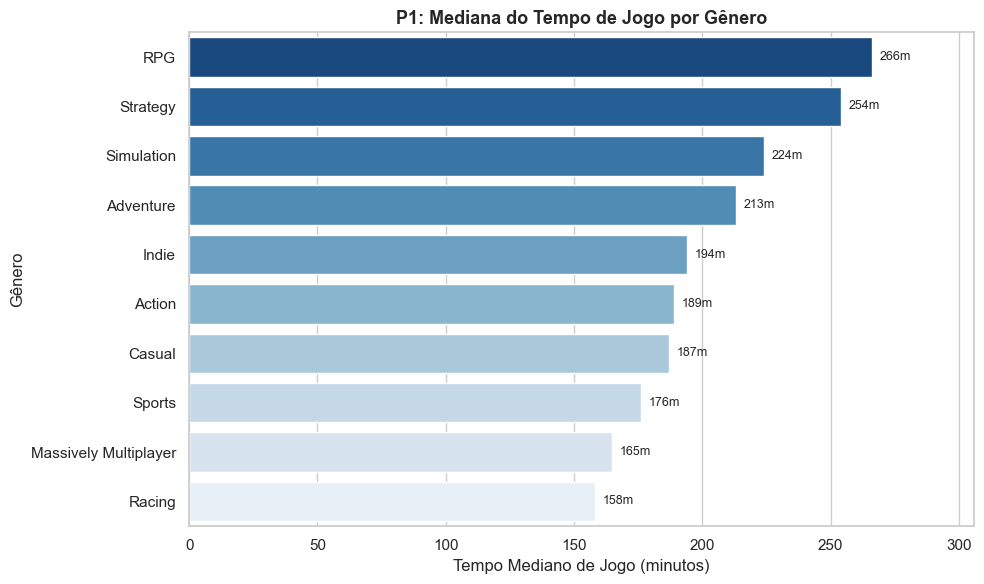

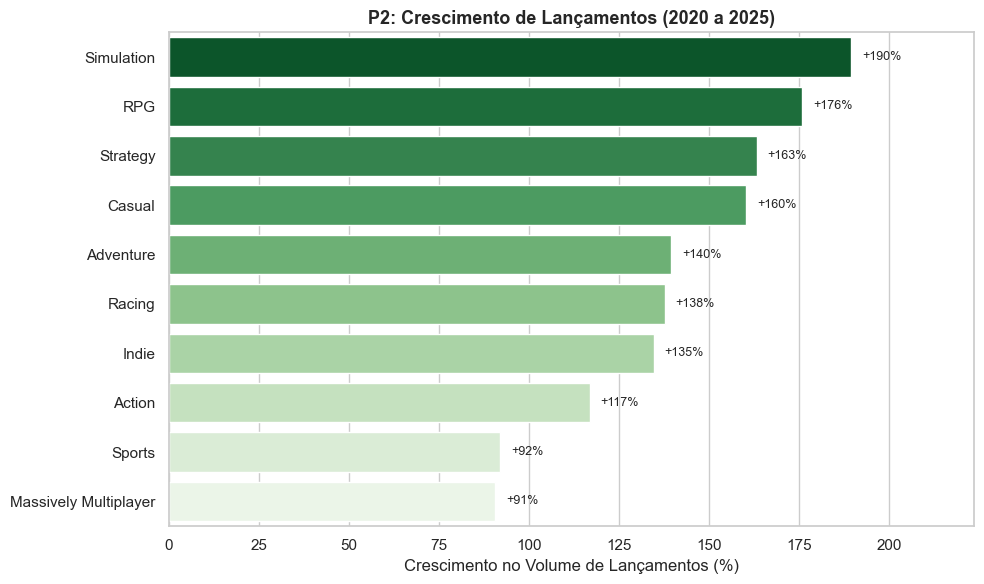

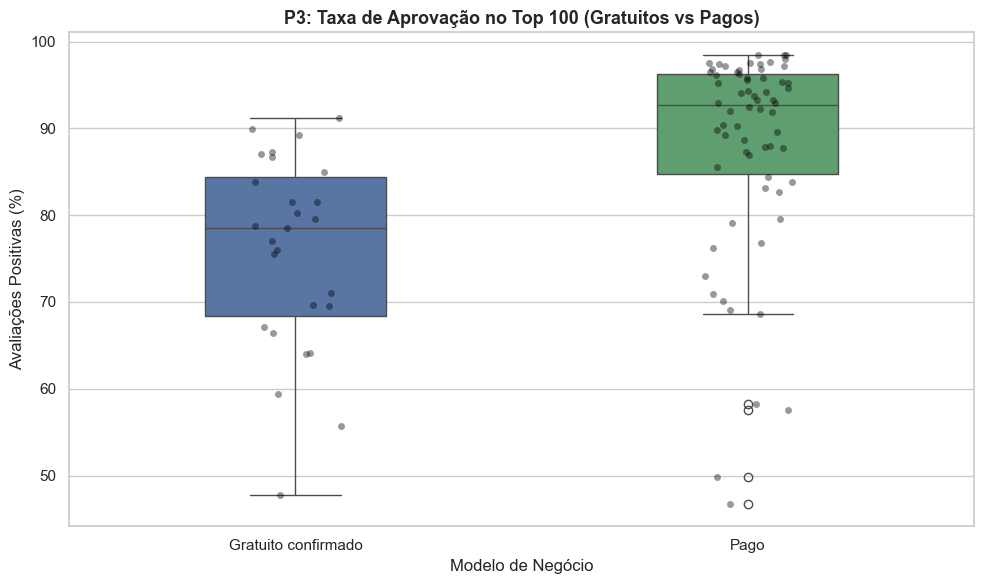


Tabela de apoio da P2 (Volume de lançamentos em 2020 vs 2025):


ano_lancamento,2020,2025,crescimento_pct
genero,,,
Simulation,1821,5272,189.5
RPG,1532,4228,176.0
Strategy,1688,4445,163.3
Casual,3887,10120,160.4
Adventure,3495,8372,139.5
Racing,302,718,137.7
Indie,6553,15383,134.7
Action,3700,8027,116.9
Sports,433,832,92.1


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

fig, ax = plt.subplots(figsize=(10,6))
axes = {0: ax}
# --- GRÁFICO 1 (P1): Tempo Mediano de Jogo por Gênero ---
ordem_gen = stats_p1.index.tolist()
sns.barplot(
    x=stats_p1["Mediana_Min"],
    y=ordem_gen,
    hue=ordem_gen,
    legend=False,
    ax=axes[0],
    palette="Blues_r"
)
axes[0].set_title("P1: Mediana do Tempo de Jogo por Gênero", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Tempo Mediano de Jogo (minutos)")
axes[0].set_ylabel("Gênero")
for i, v in enumerate(stats_p1["Mediana_Min"]):
    axes[0].text(v + 3, i, f"{v:.0f}m", va="center", fontsize=9)
axes[0].set_xlim(0, stats_p1["Mediana_Min"].max() * 1.15)


plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10,6))
axes = {1: ax}
# --- GRÁFICO 2 (P2): Crescimento Percentual de Lançamentos (2020 vs 2025) ---
df_p2 = df_final[df_final["ano_lancamento"].isin([2020, 2025])].dropna(subset=["generos_jogo"]).copy()
df_p2["genero"] = df_p2["generos_jogo"].str.split(",")
df_p2 = df_p2.explode("genero")

tabela_anos = df_p2.groupby(["genero", "ano_lancamento"]).size().unstack(fill_value=0)
tabela_anos = tabela_anos[tabela_anos[2020] >= 100].copy()
tabela_anos["crescimento_pct"] = ((tabela_anos[2025] - tabela_anos[2020]) / tabela_anos[2020]) * 100
tabela_anos = tabela_anos.sort_values("crescimento_pct", ascending=False)

sns.barplot(
    x=tabela_anos["crescimento_pct"],
    y=tabela_anos.index,
    hue=tabela_anos.index,
    legend=False,
    ax=axes[1],
    palette="Greens_r"
)
axes[1].set_title("P2: Crescimento de Lançamentos (2020 a 2025)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Crescimento no Volume de Lançamentos (%)")
axes[1].set_ylabel("")
for i, v in enumerate(tabela_anos["crescimento_pct"]):
    axes[1].text(v + 3, i, f"+{v:.0f}%", va="center", fontsize=9)
axes[1].set_xlim(0, tabela_anos["crescimento_pct"].max() * 1.18)


plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10,6))
axes = {2: ax}
# --- GRÁFICO 3 (P3): Top 100 Jogos — Gratuitos vs Pagos (Peak CCU vs Aprovação) ---
sns.boxplot(
    data=top100,
    x="Modelo",
    y="taxa_aprovacao",
    hue="Modelo",
    legend=False,
    ax=axes[2],
    width=0.4,
    palette=["#4C72B0", "#55A868"]
)
sns.stripplot(
    data=top100,
    x="Modelo",
    y="taxa_aprovacao",
    ax=axes[2],
    color="black",
    alpha=0.4,
    jitter=True
)
axes[2].set_title("P3: Taxa de Aprovação no Top 100 (Gratuitos vs Pagos)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Modelo de Negócio")
axes[2].set_ylabel("Avaliações Positivas (%)")


plt.tight_layout()
plt.show()

print("\nTabela de apoio da P2 (Volume de lançamentos em 2020 vs 2025):")
display(tabela_anos[[2020, 2025, "crescimento_pct"]].round(1))


**Resposta do grupo:**
- **P1:** RPG, Strategy e Simulation têm as maiores medianas no recorte com tempo e gênero informados.
  A relação observada não demonstra que a complexidade ou o gênero cause maior retenção longitudinal.
  Jogos com vários gêneros participam de cada grupo; as contagens por gênero não devem ser somadas como títulos distintos.
- **P2:** Simulation cresceu 189,5%, RPG 176,0%, Strategy 163,3% e Casual 160,4% entre 2020 e 2025.
  O filtro exige ao menos 100 lançamentos no ano-base, evitando percentuais dominados por denominadores pequenos.
  A comparação de dois anos indica expansão da oferta registrada, sem provar crescimento contínuo, vendas ou demanda.
- **P3:** o boxplot mostra a distribuição das taxas de aprovação por jogo no top 100 com modelo confirmado.
  A mediana dos pagos é maior (92,66% contra 78,57%). As causas dessa diferença não foram investigadas.
  Peak CCU histórico e leituras atuais do RA2 são medidas diferentes.


## 3.3 – Amostragem e Representatividade

- Descreva a origem e a abrangência dos dados.
- Analise em que medida o conjunto representa o contexto investigado.
- Identifique possíveis vieses ou limitações.
- Descreva o procedimento de amostragem, caso tenha sido utilizado.

Não é obrigatório implementar uma técnica de amostragem. Documente a análise principalmente em células Markdown; a célula de código abaixo é opcional, para análises complementares.


**Resposta do grupo:**
A base histórica Steam Games Dataset reúne registros da Steam e estimativas do SteamSpy; após preparação,
contém 124.252 itens. Não foi verificada a completude do catálogo, portanto não a tratamos como censo.
Os recortes são diferentes:
- **P1:** 25.745 jogos com tempo e gênero informados; o resultado por gênero exige pelo menos 100 jogos.
- **P2:** 30.026 jogos com gênero e lançamento em 2020 ou 2025; o gráfico exige pelo menos 100 no ano-base por gênero.
- **P3:** seleção intencional dos 100 maiores por ponto médio dos donos, pico e AppID; sete não confirmados são excluídos da comparação.
- **ML:** 23.647 jogos com tempo e gênero informados e pelo menos uma avaliação.
Tempos ausentes podem produzir viés de seleção; não foi demonstrado que as faltas sejam aleatórias.
Faixas de donos são estimativas, gêneros se sobrepõem e categorias/preços são históricos.
A regra de deduplicação pode unir edições distintas; a identificação de softwares depende dos rótulos.
Tempo de jogo aproxima engajamento, mas não mede retorno de jogadores ao longo do tempo.


In [36]:
# Utilize quantas células forem necessárias para desenvolver esta etapa.

## 3.4 – Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada. Escolha **classificação OU regressão**, conforme a natureza do problema.

1. **Problema preditivo:** defina o que a equipe pretende prever.
2. **Entradas e alvo:** identifique as características (*features*) e a variável-alvo (*target*).
3. **Treinamento e teste:** separe os dados para treinar e avaliar o modelo.
4. **Treinamento e previsões:** treine o modelo escolhido e realize previsões.
5. **Avaliação:** utilize pelo menos uma métrica adequada ao problema.
6. **Interpretação:** explique o significado dos resultados obtidos.

A equipe pode utilizar qualquer algoritmo ou ferramenta adequada; **não é obrigatório utilizar KNN ou regressão linear**. Não é necessário implementar aprendizagem online.

Se o dataset original não for adequado à aprendizagem supervisionada, a equipe poderá utilizar outro conjunto de dados nesta seção, justificando a escolha.


**Decisões do grupo:**
1. **Classificação:** estimar se o tempo mediano observado de um jogo está acima do corte de referência,
   a mediana calculada somente no treino. Isso não é uma medida direta de retenção longitudinal.
2. **Target:** classe 1 se o tempo mediano supera esse corte, 0 caso contrário.
3. **Features:** preço, ano, aprovação, log(1+avaliações), indicadores das três categorias de modelo de negócio
   e presença dos dez gêneros principais. Não usamos o tempo de jogo como entrada.
4. **Treino/teste:** divisão aleatória 80%/20%, semente 42, antes de definir o corte; não se exige equilíbrio exato.
5. **Modelo:** Random Forest com 150 árvores e profundidade máxima 12. Avaliação com acurácia, acurácia balanceada,
   precisão, recall, F1 e matriz de confusão; referência que sempre prevê a classe mais frequente do treino.
O teste não é usado para escolher o corte ou hiperparâmetros. Como as avaliações já existem após o lançamento,
o experimento não comprova previsão pré-lançamento nem desempenho em novos períodos.


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,classification_report,confusion_matrix
df_ml=df_final.dropna(subset=['Median playtime forever','generos_jogo']).copy()
df_ml['total_avaliacoes']=df_ml['Positive']+df_ml['Negative']
df_ml=df_ml[df_ml['total_avaliacoes'].gt(0)].copy()
df_ml['taxa_aprovacao']=df_ml['Positive']/df_ml['total_avaliacoes']
df_ml['log_total_avaliacoes']=np.log1p(df_ml['total_avaliacoes'])
generos_ml=['Action','Adventure','Casual','Indie','Massively Multiplayer','RPG','Simulation','Sports','Strategy','Racing']
listas_ml=df_ml['generos_jogo'].str.split(',')
for g in generos_ml:df_ml['gen_'+g]=listas_ml.apply(lambda xs:int(g in xs))
for tipo,nome in [('Gratuito confirmado','modelo_gratuito'),('Pago','modelo_pago'),('Não confirmado','modelo_nao_confirmado')]:
    df_ml[nome]=df_ml['modelo_negocio'].eq(tipo).astype(int)
features=['Price','ano_lancamento','taxa_aprovacao','log_total_avaliacoes',
    'modelo_gratuito','modelo_pago','modelo_nao_confirmado']+['gen_'+g for g in generos_ml]
treino,teste=train_test_split(df_ml,test_size=.2,random_state=42)
corte=treino['Median playtime forever'].median()
X_train,X_test=treino[features],teste[features]
y_train=treino['Median playtime forever'].gt(corte).astype(int)
y_test=teste['Median playtime forever'].gt(corte).astype(int)
assert set(treino.index).isdisjoint(teste.index)
assert 'Median playtime forever' not in features
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
modelo=RandomForestClassifier(n_estimators=150,max_depth=12,random_state=42,n_jobs=2)
referencia=DummyClassifier(strategy='most_frequent')
modelo.fit(X_train,y_train);referencia.fit(X_train,y_train)
pred=modelo.predict(X_test);pred_ref=referencia.predict(X_test)
def metricas(real,prev):
    return {'Acuracia':accuracy_score(real,prev),'Acuracia_balanceada':balanced_accuracy_score(real,prev),
        'F1_alta':f1_score(real,prev,zero_division=0),'F1_macro':f1_score(real,prev,average='macro',zero_division=0)}
avaliacao=pd.DataFrame({'Referência: maioria':metricas(y_test,pred_ref),'Random Forest':metricas(y_test,pred)}).T
print(f'Jogos no ML: {len(df_ml):,} | treino: {len(treino):,} | teste: {len(teste):,}')
print(f'Tempo acima do corte: > {corte:.0f} minutos (mediana do treino).')
display(pd.DataFrame({'Treino':y_train.value_counts(),'Teste':y_test.value_counts()}).rename(index={0:'Até o corte',1:'Acima do corte'}))
display(avaliacao.round(4))
print(classification_report(y_test,pred,labels=[0,1],target_names=['Até o corte','Acima do corte'],zero_division=0))


Jogos no ML: 23,647 | treino: 18,917 | teste: 4,730
Tempo acima do corte: > 204 minutos (mediana do treino).


,Treino,Teste
Median playtime forever,,
Até o corte,9460,2314
Acima do corte,9457,2416


,Acuracia,Acuracia_balanceada,F1_alta,F1_macro
Referência: maioria,0.4892,0.5000,0.0000,0.3285
Random Forest,0.6611,0.6627,0.6394,0.6599


                precision    recall  f1-score   support

   Até o corte       0.63      0.74      0.68      2314
Acima do corte       0.70      0.59      0.64      2416

      accuracy                           0.66      4730
     macro avg       0.67      0.66      0.66      4730
  weighted avg       0.67      0.66      0.66      4730



### Avaliação e interpretação

Compare as previsões com os valores reais do conjunto de teste, calcule a métrica escolhida e interprete o resultado no contexto do problema preditivo.


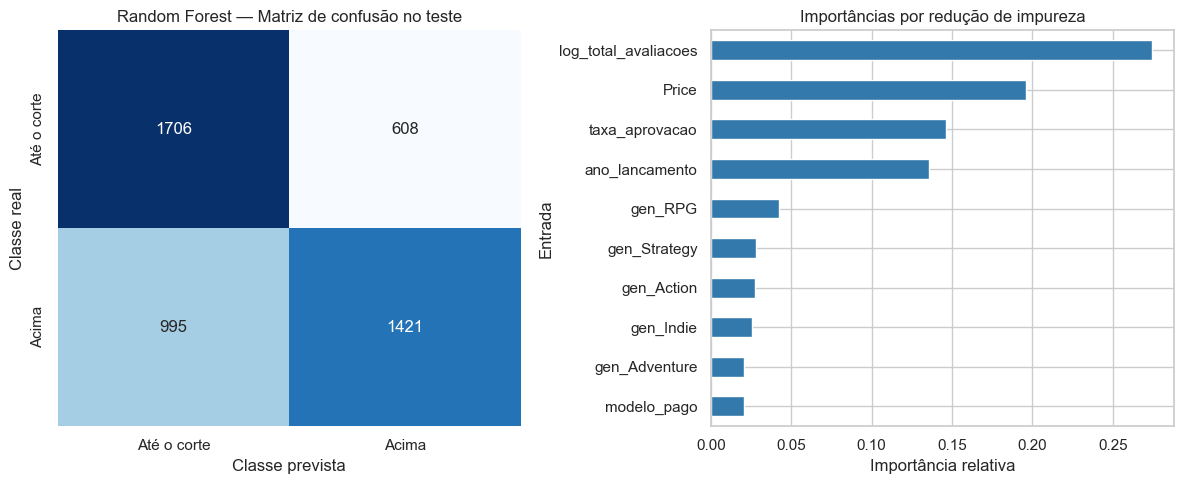

O modelo acertou **66.11%** das classificações no teste, ante **48.92%** da referência (diferença de **17.19 pontos percentuais**). Houve **995** jogos acima do corte previstos como até o corte e **608** no sentido inverso. Erros de classificação não são uma porcentagem da variância do tempo de jogo.

In [38]:
from IPython.display import Markdown
cm=confusion_matrix(y_test,pred,labels=[0,1])
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[0],
    xticklabels=['Até o corte','Acima'],yticklabels=['Até o corte','Acima'])
axes[0].set(title='Random Forest — Matriz de confusão no teste',xlabel='Classe prevista',ylabel='Classe real')
importancias=pd.Series(modelo.feature_importances_,index=features).sort_values()
importancias.tail(10).plot.barh(ax=axes[1],color='#3479ab')
axes[1].set(title='Importâncias por redução de impureza',xlabel='Importância relativa',ylabel='Entrada')
fig.tight_layout();plt.show()
acuracia=accuracy_score(y_test,pred)
base_acc=accuracy_score(y_test,pred_ref)
display(Markdown(f'O modelo acertou **{acuracia:.2%}** das classificações no teste, ante **{base_acc:.2%}** da referência '
    f'(diferença de **{100*(acuracia-base_acc):.2f} pontos percentuais**). '
    f'Houve **{cm[1,0]}** jogos acima do corte previstos como até o corte e **{cm[0,1]}** no sentido inverso. '
    'Erros de classificação não são uma porcentagem da variância do tempo de jogo.'))


**Resposta do grupo:**
A Random Forest atingiu 66,11% de acurácia no teste, contra 48,92% da referência por classe majoritária;
a acurácia balanceada foi 66,27%. O F1 é cerca de 0,68 para até o corte e 0,64 para acima do corte.
Ainda há erros relevantes: o modelo não deve ser apresentado como garantia de sucesso de um jogo.
Importâncias indicam o uso das entradas nas divisões da floresta, não a direção do efeito nem causalidade.
Importâncias por impureza podem favorecer variáveis contínuas e são influenciadas por entradas correlacionadas.
Erros de classificação não equivalem a porcentagem de variância do tempo não explicada.
A avaliação vale para um único teste aleatório dos jogos com dados; não foi validada temporalmente.


## 3.5 – Conclusões do RA3

Apresente brevemente:

- As principais descobertas das análises estatísticas.
- Os resultados mais relevantes das visualizações.
- A interpretação do desempenho do modelo de Machine Learning.
- As limitações identificadas.
- A relação dos resultados com o problema definido no projeto.


**Conclusões do grupo:**
- **Estatística:** médias acima das medianas e dispersão elevada indicam caudas e valores extremos.
  Mediana e IQR ajudam a descrever os títulos típicos do recorte sem ignorar essa variabilidade.
- **P1:** RPG (266 min), Strategy (254 min) e Simulation (224 min) lideram as medianas entre os gêneros elegíveis.
- **P2:** os maiores crescimentos relativos entre 2020 e 2025 são Simulation (+189,5%), RPG (+176,0%) e Strategy (+163,3%).
  Isso descreve oferta registrada, não demanda ou lucratividade.
- **P3:** entre os 93 jogos de modelo confirmado no top 100, há 27 gratuitos confirmados e 66 pagos.
  Picos medianos são 14.169 e 13.517,5; aprovações medianas por jogo são 78,57% e 92,66%, respectivamente.
- **Modelo:** acurácia de 66,11%, superior à referência de 48,92%, com corte de 204 minutos calculado só no treino.
  O modelo classifica tempo observado usando metadados já disponíveis, sem validar previsão pré-lançamento.
- **Limites:** ausência de tempos, cobertura não comprovadamente completa, donos estimados, categorias históricas,
  gêneros sobrepostos e um único teste aleatório restringem generalizações e impedem conclusões causais.
Os resultados oferecem referências para investigar gêneros, expansão da oferta e diferenças entre líderes do catálogo,
mas não garantem que escolher um gênero ou modelo de negócio provoque maior engajamento, aprovação ou sucesso comercial.
